<a href="https://colab.research.google.com/github/vzavala/DesignOfExperiments/blob/main/Python/GaussianProcessDesign.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the book's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('statsbook'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DesignOfExperiments.git statsbook')
        os.system('git -C statsbook sparse-checkout set Python/Data Python/Support')
    path = 'statsbook/Python/'

Gaussian process to guide the experimental search for pectin extraction (Victor Z, UW-Madison, 2026).

| Slides | Python | Meaning |
|---|---|---|
| $\mathbf{x}$ | `x` | scaled temperature, time, acid concentration |
| $y$ | `y` | measured yields [%] |
| $m(\mathbf{x})$ | `m` | GP mean prediction |
| $\sigma(\mathbf{x})$ | `s` | GP standard deviation |
| $\max\; y(\mathbf{x})$ | `x_exploit` | exploitation: largest predicted yield |
| $\max\; \mathbb{V}[y(\mathbf{x})]$ | `x_explore` | exploration: largest uncertainty (information gain) |

**Note:** This notebook builds the GP model of the solvent-extraction example of the slides and uses it to search the design space for the highest predicted yield and for the largest information gain.

kernel: 1.71**2 * RBF(length_scale=2.17)
R^2 = 0.999


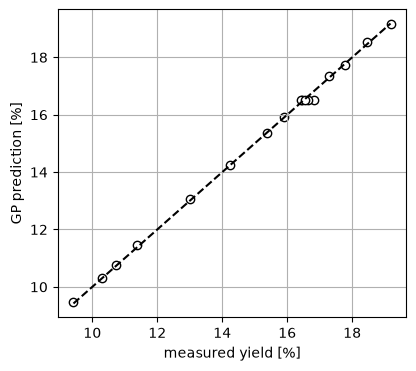

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel

D = np.loadtxt(path + "Data/box_behnken.dat")
x, y = D[:, :3], D[:, 3]

gp = GaussianProcessRegressor(kernel=ConstantKernel(1.0, (1e-2, 1e3)) * RBF(1.0, (1e-2, 1e2)), normalize_y=True,
                              alpha=0.01, n_restarts_optimizer=10, random_state=0)
gp.fit(x, y)
print("kernel:", gp.kernel_)
y_hat = gp.predict(x)
R2 = 1 - np.sum((y - y_hat)**2) / np.sum((y - y.mean())**2)
print(f"R^2 = {R2:.3f}")

plt.figure(figsize=(4.5, 4))
plt.plot([y.min(), y.max()], [y.min(), y.max()], "k--")
plt.scatter(y, y_hat, facecolors="w", edgecolors="k")
plt.xlabel("measured yield [%]"); plt.ylabel("GP prediction [%]")
plt.grid(True); plt.show()

Predict the mean and the uncertainty on a grid of the design space.

In [3]:
g = np.linspace(-1, 1, 11)
grid = np.array(np.meshgrid(g, g, g, indexing="ij")).reshape(3, -1).T
m, s = gp.predict(grid, return_std=True)

def physical(x):
    """Scaled conditions to temperature [C], time [h], acid concentration [%]."""
    return np.array([85, 1.5, 0.2]) + np.asarray(x) * np.array([15, 0.5, 0.1])

x_exploit, x_explore = grid[np.argmax(m)], grid[np.argmax(s)]
print(f"exploit: x = {np.round(x_exploit, 2)}, physical {np.round(physical(x_exploit), 3)}: "
      f"m = {m.max():.2f} %, s = {s[np.argmax(m)]:.2f} %")
print(f"explore: x = {np.round(x_explore, 2)}, physical {np.round(physical(x_explore), 3)}: "
      f"m = {m[np.argmax(s)]:.2f} %, s = {s.max():.2f} %")
print(f"best measured yield = {y.max():.2f} %")

exploit: x = [1.  0.4 0.2], physical [100.     1.7    0.22]: m = 19.60 %, s = 0.28 %
explore: x = [-1.  1.  1.], physical [70.   2.   0.3]: m = 11.23 %, s = 0.60 %
best measured yield = 19.18 %


Predicted yield (left) and its uncertainty (right) over the design space; squares are the
experiments and stars the conditions of maximum yield and maximum uncertainty.

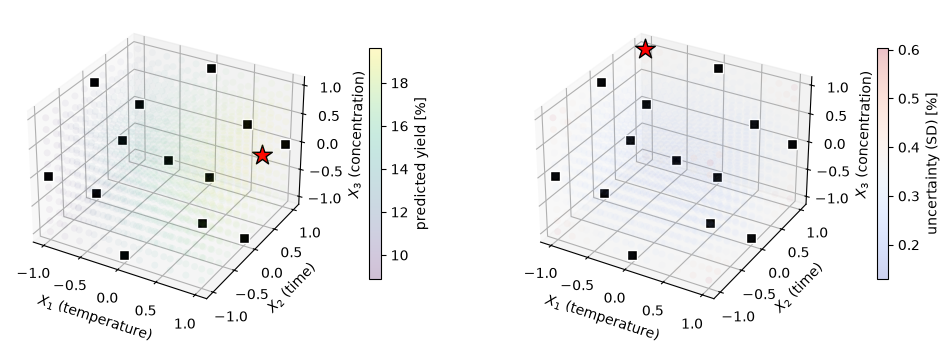

In [4]:
fig = plt.figure(figsize=(12, 5))
for k, (v, star, cmap, lab) in enumerate([(m, x_exploit, "viridis", "predicted yield [%]"),
                                          (s, x_explore, "coolwarm", "uncertainty (SD) [%]")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    p = ax.scatter(*grid.T, c=v, cmap=cmap, alpha=0.25, s=25, edgecolors="none")
    ax.scatter(*x.T, color="black", marker="s", edgecolor="white", s=60, depthshade=False)
    ax.scatter(*star, color="red", marker="*", edgecolor="black", s=220, depthshade=False)
    ax.set_xlabel("$X_1$ (temperature)"); ax.set_ylabel("$X_2$ (time)"); ax.set_zlabel("$X_3$ (concentration)")
    fig.colorbar(p, ax=ax, label=lab, shrink=0.6, pad=0.12)
plt.show()

The experiments of largest information gain, in order of uncertainty:

In [5]:
top = np.argsort(s, kind="stable")[::-1][:10]
print(pd.DataFrame(np.column_stack([physical(grid[top]), m[top], s[top]]),
                   columns=["T [C]", "time [h]", "conc [%]", "m [%]", "s [%]"]).round(2).to_string())

   T [C]  time [h]  conc [%]  m [%]  s [%]
0   70.0       2.0      0.30  11.23    0.6
1  100.0       1.0      0.10  15.78    0.6
2  100.0       2.0      0.10  17.50    0.6
3   70.0       1.0      0.30   9.59    0.6
4  100.0       2.0      0.30  18.30    0.6
5   70.0       2.0      0.10  11.09    0.6
6   70.0       1.0      0.10   8.87    0.6
7  100.0       1.0      0.30  17.17    0.6
8  100.0       1.0      0.12  16.33    0.5
9  100.0       2.0      0.12  18.00    0.5


**Note:** The GP interpolates the data and flags the regions it has not seen: the corners of the cube, where the Box-Behnken design has no experiments, have the largest uncertainty. Exploitation suggests high temperature; exploration suggests a corner.